# Lab 3 FDSAI (2026-2027)
Data visualization with Matplotlib / NumPy / Pandas. Run all cells top to bottom.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Global style: readable fonts and consistent look
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## Exercise 1 – Screen time over the week

In [3]:
# Data from the table
df_screen = pd.DataFrame({
    "Day": ["Mo", "Tu", "We", "Th", "Fr", "Sa", "Su"],
    "ScreenTime": [5, 6, 4, 7, 8, 10, 9],
})
df_screen

,Day,ScreenTime
0,Mo,5
1,Tu,6
2,We,4
3,Th,7
4,Fr,8
5,Sa,10
6,Su,9


### 1a + 1b) Line chart with title, labelled axes, units and grid

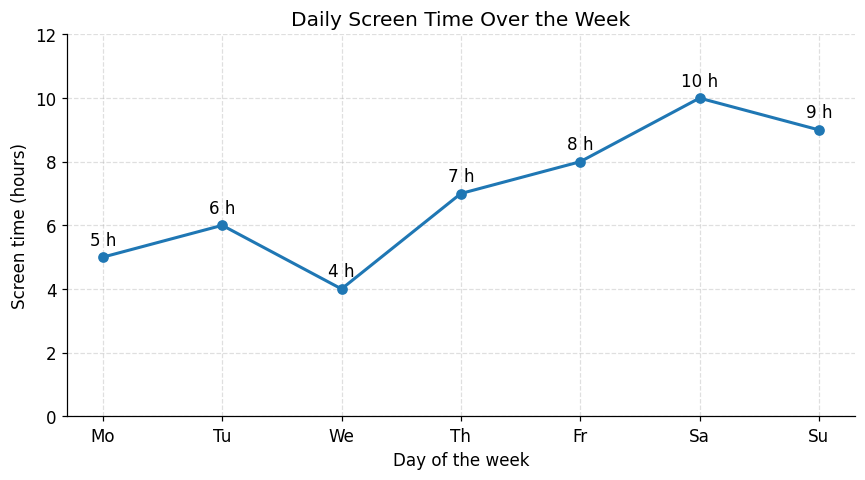

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_screen["Day"], df_screen["ScreenTime"], marker="o", linewidth=2, color="tab:blue")

# Annotate each point with its value
for x, y in zip(df_screen["Day"], df_screen["ScreenTime"]):
    ax.annotate(f"{y} h", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")

ax.set_title("Daily Screen Time Over the Week")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Screen time (hours)")
ax.set_ylim(0, 12)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Grid test:** a light, dashed grid helps to read approximate values. A heavy/dark grid competes with the data, so `alpha` is kept low. With direct value labels the grid is optional.

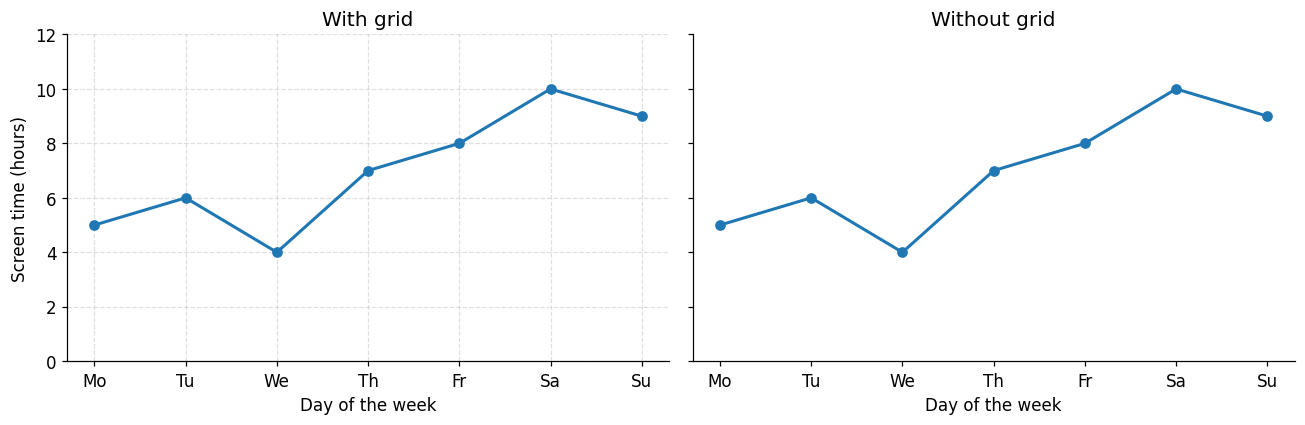

In [5]:
# Same chart WITHOUT grid, to compare side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, grid in zip(axes, [True, False]):
    ax.plot(df_screen["Day"], df_screen["ScreenTime"], marker="o", linewidth=2)
    ax.set_title("With grid" if grid else "Without grid")
    ax.set_xlabel("Day of the week")
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_ylim(0, 12)
axes[0].set_ylabel("Screen time (hours)")
plt.tight_layout()
plt.show()

### 1c) Bar chart version

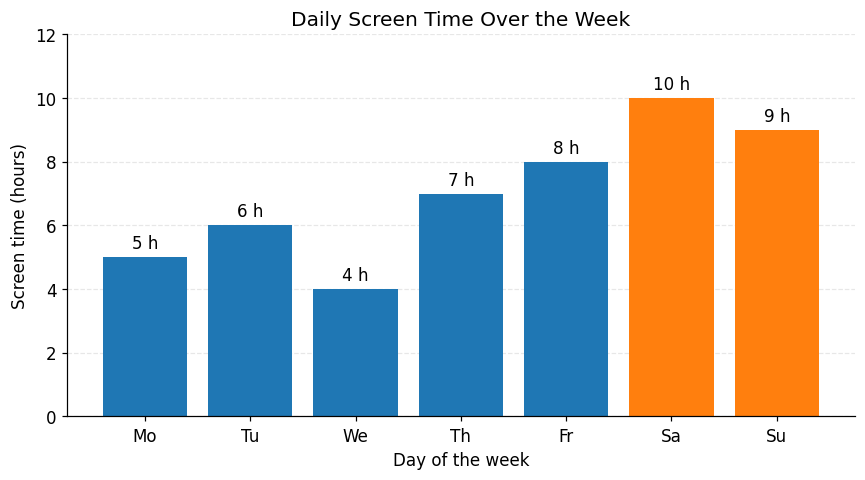

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# Highlight the weekend in a different color
colors = ["tab:blue"] * 5 + ["tab:orange"] * 2
bars = ax.bar(df_screen["Day"], df_screen["ScreenTime"], color=colors)
ax.bar_label(bars, fmt="%d h", padding=3)   # value labels on top of the bars

ax.set_title("Daily Screen Time Over the Week")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Screen time (hours)")
ax.set_ylim(0, 12)               # bars MUST start at zero
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)           # grid behind the bars
plt.tight_layout()
plt.show()

**Discussion – which chart communicates the pattern more clearly?**

- The **line chart** is better for the *pattern/trend*: the slope shows that screen time rises from Wednesday (4 h) to the weekend peak on Saturday (10 h), then drops slightly on Sunday. Lines emphasise change between consecutive points.
- The **bar chart** is better for *comparing exact values* between days (e.g. Saturday is 2.5x Wednesday) and for highlighting groups (weekdays vs. weekend).
- Because the x-axis is an ordered time sequence (days of a week), the **line chart communicates the pattern more clearly**, while the bar chart is better when the reader needs to compare individual days.

## Exercise 2 – Plotting functions (best practices)
Best practices used: one function per subplot with its own title, labelled axes, enough sample points for smooth curves, axis lines at 0, light grid, readable limits, and a legend/formula in the title.

Functions:
- f1(x) = max(0, x) – ReLU
- f2(x) = (e^(2x) − 1) / (e^(2x) + 1) – hyperbolic tangent
- f3(x) = 1 / (1 + e^(−x)) – sigmoid
- f4(x) = 1 / (σ·√(2π)) · e^(−(x−μ)² / (2σ²)) – Gaussian (normal) density, with μ = 0, σ = 1 (*the formula was garbled in the PDF, so this is my reading of it*)
- f5(x) = 0.5·x·(1 + tanh(0.797885·x + 0.035677·x³)) – GELU (tanh approximation)

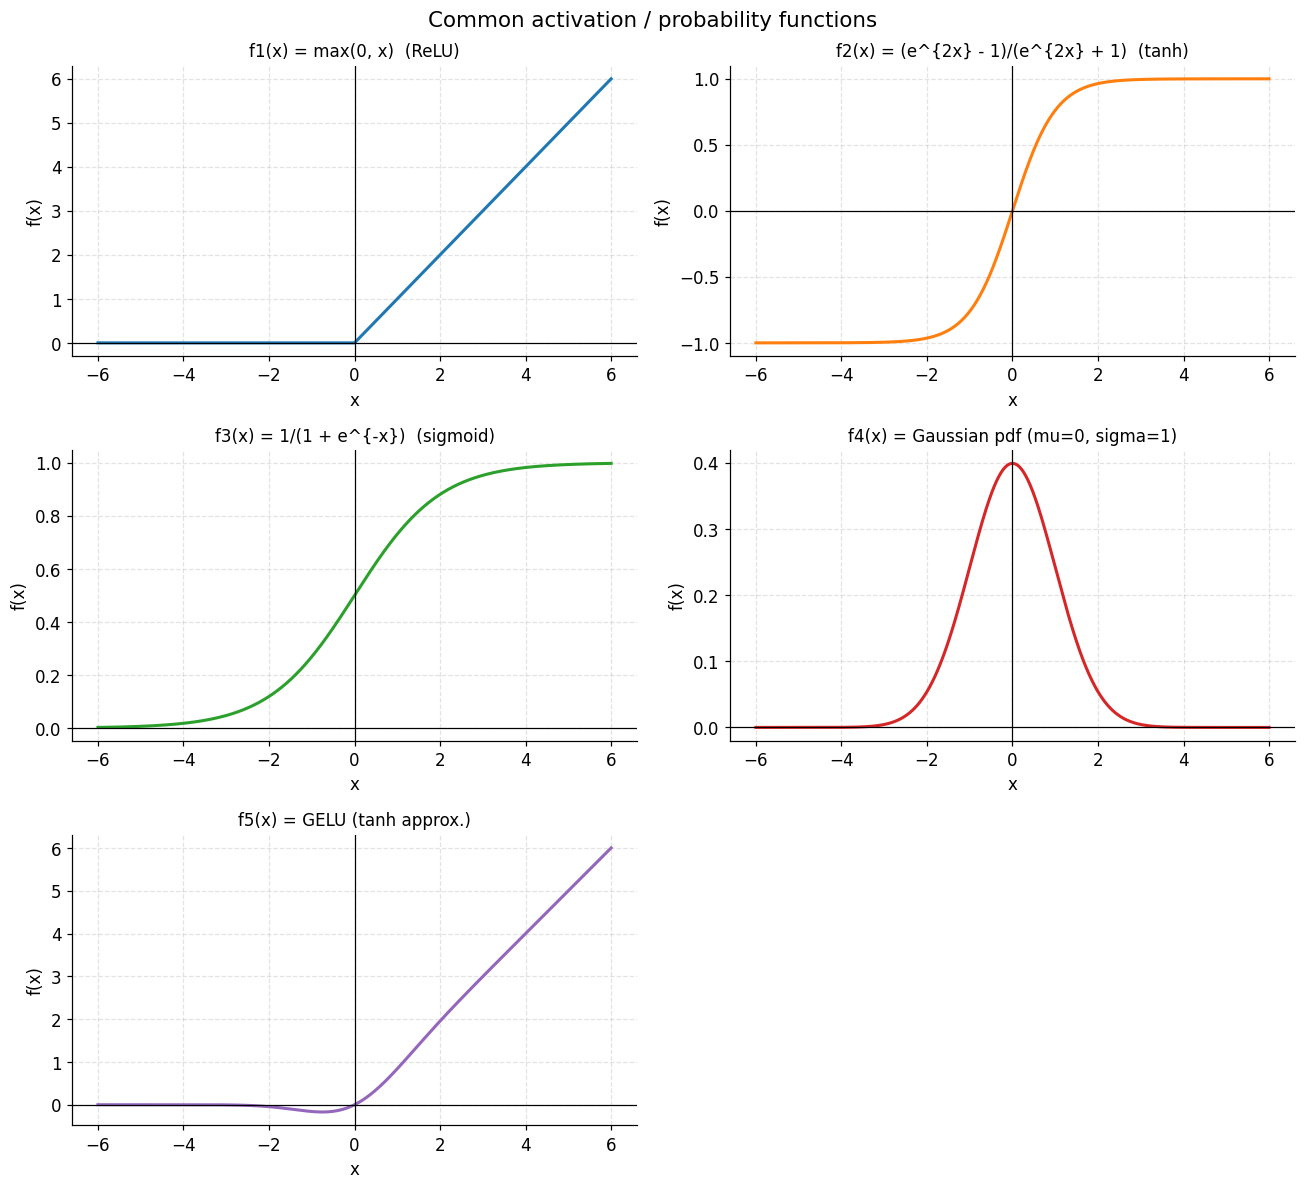

In [7]:
x = np.linspace(-6, 6, 1000)   # dense grid -> smooth curves

def f1(x):  # ReLU
    return np.maximum(0, x)

def f2(x):  # tanh written with exponentials
    return (np.exp(2 * x) - 1) / (np.exp(2 * x) + 1)

def f3(x):  # sigmoid
    return 1 / (1 + np.exp(-x))

def f4(x, mu=0.0, sigma=1.0):  # Gaussian probability density function
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

def f5(x):  # GELU (tanh approximation)
    return 0.5 * x * (1 + np.tanh(0.797885 * x + 0.035677 * x ** 3))

funcs = [
    (f1, "f1(x) = max(0, x)  (ReLU)", "tab:blue"),
    (f2, "f2(x) = (e^{2x} - 1)/(e^{2x} + 1)  (tanh)", "tab:orange"),
    (f3, "f3(x) = 1/(1 + e^{-x})  (sigmoid)", "tab:green"),
    (f4, "f4(x) = Gaussian pdf (mu=0, sigma=1)", "tab:red"),
    (f5, "f5(x) = GELU (tanh approx.)", "tab:purple"),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 11))
axes = axes.ravel()
for ax, (f, title, color) in zip(axes, funcs):
    ax.plot(x, f(x), color=color, linewidth=2)
    ax.axhline(0, color="black", linewidth=0.8)   # reference axes through the origin
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True, linestyle="--", alpha=0.35)
axes[-1].axis("off")   # 5 plots on a 3x2 grid -> hide the unused cell
plt.suptitle("Common activation / probability functions", fontsize=14)
plt.tight_layout()
plt.show()

### Comparison of all functions on the same axes
Only the functions with a similar output range are compared directly (tanh, sigmoid, GELU, ReLU).

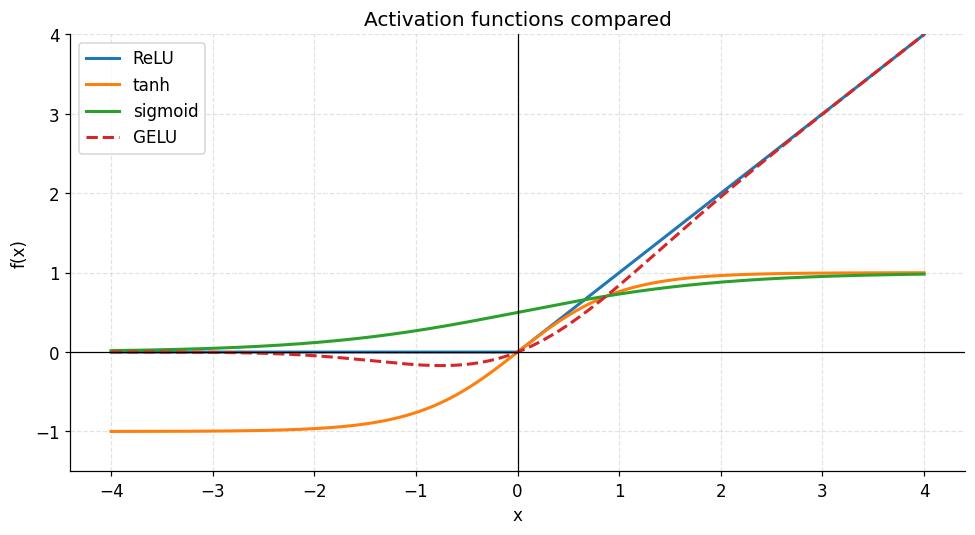

In [8]:
x2 = np.linspace(-4, 4, 800)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x2, f1(x2), label="ReLU", linewidth=2)
ax.plot(x2, f2(x2), label="tanh", linewidth=2)
ax.plot(x2, f3(x2), label="sigmoid", linewidth=2)
ax.plot(x2, f5(x2), label="GELU", linewidth=2, linestyle="--")
ax.set_ylim(-1.5, 4)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Activation functions compared")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

## Exercise 3 – Student scores and outliers

In [9]:
df_scores = pd.DataFrame({
    "Student": range(1, 11),
    "Score": [70, 75, 78, 82, 74, 90, 92, 95, 60, 100],
})
df_scores

,Student,Score
0,1,70
1,2,75
2,3,78
3,4,82
4,5,74
5,6,90
6,7,92
7,8,95
8,9,60
9,10,100


### 3a) Boxplot

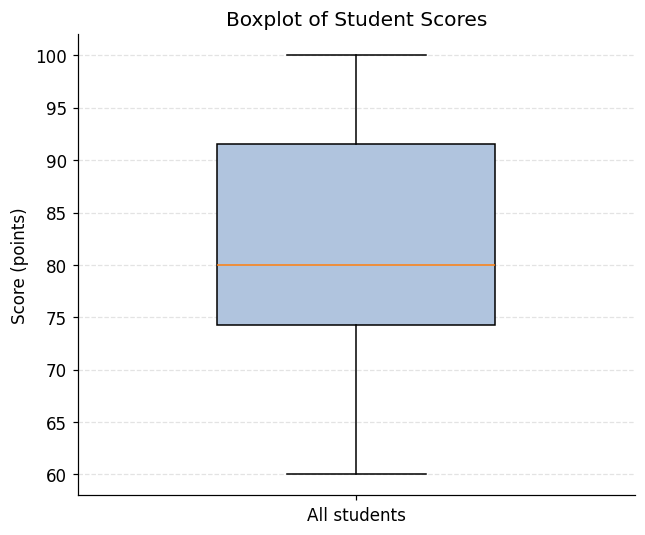

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(df_scores["Score"], vert=True, patch_artist=True, widths=0.5,
           boxprops=dict(facecolor="lightsteelblue"),
           flierprops=dict(marker="o", markerfacecolor="red", markersize=8))  # outliers drawn in red
ax.set_title("Boxplot of Student Scores")
ax.set_ylabel("Score (points)")
ax.set_xticks([1])
ax.set_xticklabels(["All students"])
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

In [11]:
# IQR rule: a point is an outlier if it is outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
q1 = df_scores["Score"].quantile(0.25)
q3 = df_scores["Score"].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Lower fence = {lower:.2f}, Upper fence = {upper:.2f}")

df_scores["Outlier"] = (df_scores["Score"] < lower) | (df_scores["Score"] > upper)
print("\nOutliers found:")
print(df_scores[df_scores["Outlier"]] if df_scores["Outlier"].any() else "None - all scores are inside the fences.")

Q1 = 74.25, Q3 = 91.5, IQR = 17.25
Lower fence = 48.38, Upper fence = 117.38

Outliers found:
None - all scores are inside the fences.


With the standard 1.5×IQR rule **no real outliers** are detected (60 and 100 are the extremes but still inside the fences). The code below is written generically, so any outlier would be colored differently.

### 3b) Scatter plot with outliers highlighted

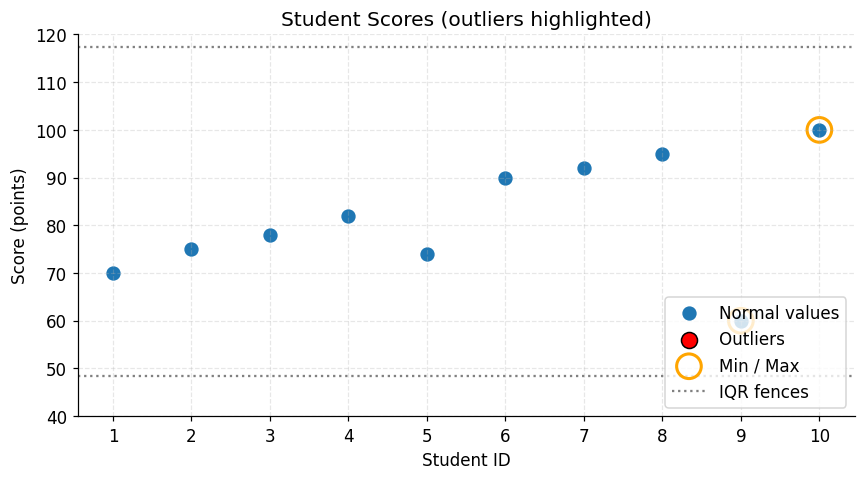

In [12]:
normal = df_scores[~df_scores["Outlier"]]
outl = df_scores[df_scores["Outlier"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(normal["Student"], normal["Score"], color="tab:blue", s=70, label="Normal values")
ax.scatter(outl["Student"], outl["Score"], color="red", s=110, edgecolor="black", label="Outliers")

extremes = df_scores.loc[[df_scores["Score"].idxmin(), df_scores["Score"].idxmax()]]
ax.scatter(extremes["Student"], extremes["Score"], facecolors="none", edgecolors="orange",
           s=260, linewidths=2, label="Min / Max")

# Fences as reference lines
ax.axhline(lower, color="gray", linestyle=":", label="IQR fences")
ax.axhline(upper, color="gray", linestyle=":")

ax.set_title("Student Scores (outliers highlighted)")
ax.set_xlabel("Student ID")
ax.set_ylabel("Score (points)")
ax.set_xticks(df_scores["Student"])
ax.set_ylim(40, 120)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 3c) How misleading axis scales can make outliers look "normal"

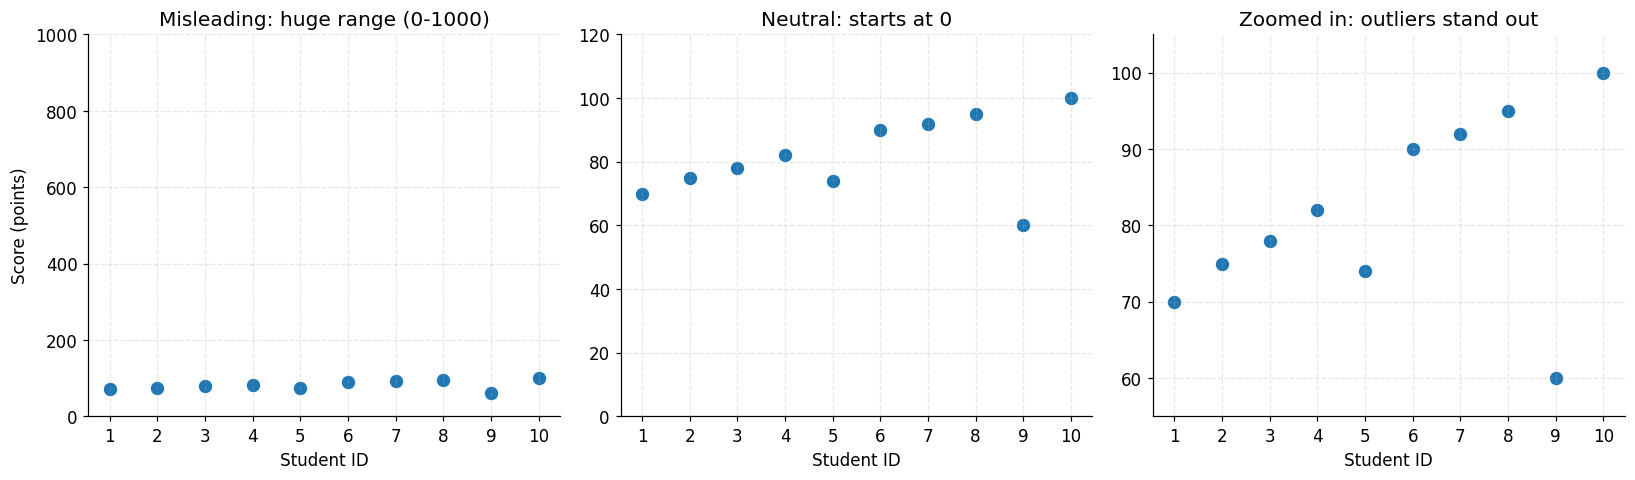

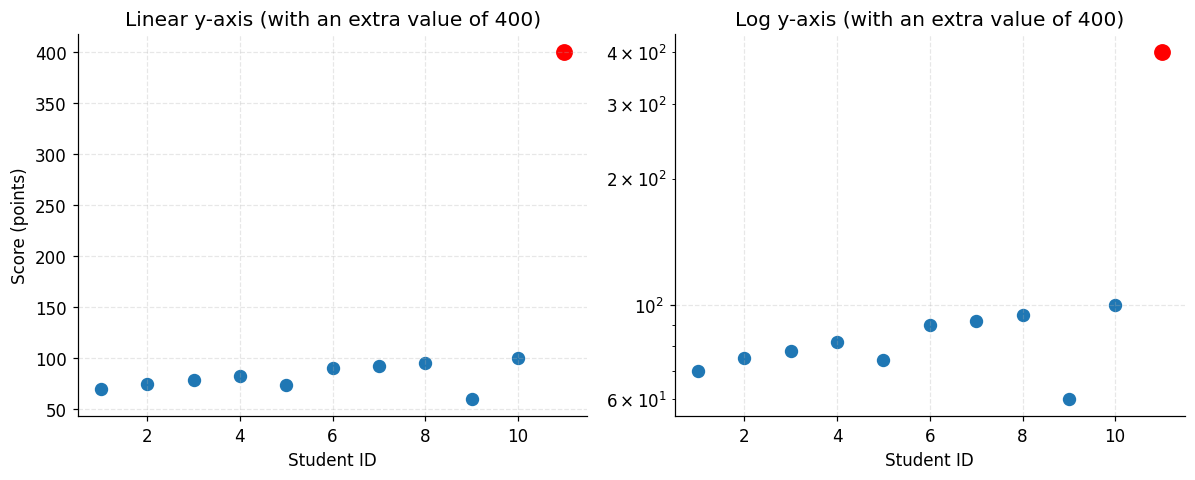

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
configs = [
    ((0, 1000), "Misleading: huge range (0-1000)"),
    ((0, 120),  "Neutral: starts at 0"),
    ((55, 105), "Zoomed in: outliers stand out"),
]
for ax, (ylim, title) in zip(axes, configs):
    ax.scatter(df_scores["Student"], df_scores["Score"], color="tab:blue", s=60)
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.set_xlabel("Student ID")
    ax.set_xticks(df_scores["Student"])
    ax.grid(True, linestyle="--", alpha=0.3)
axes[0].set_ylabel("Score (points)")
plt.tight_layout()
plt.show()

demo = np.append(df_scores["Score"].values, 400)   # artificial extreme value
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.scatter(range(1, len(demo) + 1), demo, color="tab:blue", s=60)
    ax.scatter(len(demo), demo[-1], color="red", s=100)   # the artificial outlier
    ax.set_yscale(scale)
    ax.set_title(f"{scale.capitalize()} y-axis (with an extra value of 400)")
    ax.set_xlabel("Student ID")
    ax.grid(True, linestyle="--", alpha=0.3)
axes[0].set_ylabel("Score (points)")
plt.tight_layout()
plt.show()

**Answer to 3c.** Outliers are judged visually by how far they sit from the rest of the points. The axis scale controls that distance:

- **Very wide axis range** (e.g. 0–1000 for scores between 60 and 100): all points get squeezed into a thin band, so a value like 60 or 100 looks no different from the rest.
- **Log scale**: it compresses large values, so an extreme value (such as 400 in the demo) looks much closer to the others than it really is.
- **Truncated or inconsistent axes / different scales between compared charts**: can exaggerate small differences or hide big ones.

**Best practice:** use an honest scale (start at 0 for bars, a reasonable range for scatter plots), say clearly when a log scale is used, and do not rely only on the picture – support it with numbers (IQR fences, z-scores) and a boxplot.